In [1]:
import pandas as pd

df = pd.read_csv("/kaggle/input/datasets/arjunyadav99/indian-agricultural-mandi-prices-20232025/Agriculture_price_dataset.csv")

print(df.head())
print(df.columns)
print(df.shape)

           STATE District Name        Market Name Commodity           Variety  \
0    Maharashtra        nashik  Lasalgaon(Niphad)     Wheat  Maharashtra 2189   
1    Maharashtra        satara              Patan    Tomato             Other   
2  Uttar Pradesh      mainpuri              Bewar    Potato             Local   
3      Rajasthan   chittorgarh          Nimbahera     Wheat             Other   
4      Rajasthan    pratapgarh         Pratapgarh     Onion             Other   

  Grade  Min_Price  Max_Price  Modal_Price Price Date  
0   FAQ     2172.0     2399.0       2300.0   6/6/2023  
1   FAQ     1000.0     1500.0       1250.0   6/6/2023  
2   FAQ      800.0      820.0        810.0   6/6/2023  
3   FAQ     2040.0     2668.0       2300.0   6/6/2023  
4   FAQ      476.0     1043.0        617.0   6/6/2023  
Index(['STATE', 'District Name', 'Market Name', 'Commodity', 'Variety',
       'Grade', 'Min_Price', 'Max_Price', 'Modal_Price', 'Price Date'],
      dtype='object')
(737392, 10

In [2]:
# Filter for your 3 commodities
df_filtered = df[df["Commodity"].isin(["Onion", "Potato", "Tomato"])].copy()

# Check how many rows you have
print(df_filtered["Commodity"].value_counts())
print(f"\nTotal rows: {len(df_filtered)}")
print(f"Date range: {df_filtered['Price Date'].min()} to {df_filtered['Price Date'].max()}")

Commodity
Potato    327332
Onion     298658
Tomato     26644
Name: count, dtype: int64

Total rows: 652634
Date range: 1/1/2024 to 9/9/2024


In [3]:
import pandas as pd

# Convert date column
df_filtered["Price Date"] = pd.to_datetime(df_filtered["Price Date"], format="%m/%d/%Y")

# Drop rows with missing modal price
df_filtered = df_filtered.dropna(subset=["Modal_Price"])

# Aggregate: average modal price per commodity per date (across all markets)
df_agg = df_filtered.groupby(["Commodity", "Price Date"])["Modal_Price"].mean().reset_index()

# Sort by commodity and date
df_agg = df_agg.sort_values(["Commodity", "Price Date"])

print(df_agg.head())
print(f"\nAggregated rows: {len(df_agg)}")
print(df_agg.groupby("Commodity").size())

  Commodity Price Date  Modal_Price
0     Onion 2023-06-06  1334.767346
1     Onion 2023-06-07  1383.344565
2     Onion 2023-06-08  1406.423859
3     Onion 2023-06-09  1353.329913
4     Onion 2023-06-10  1291.675134

Aggregated rows: 1538
Commodity
Onion     647
Potato    737
Tomato    154
dtype: int64


In [4]:
# Save each commodity separately
for crop in ["Onion", "Potato", "Tomato"]:
    crop_df = df_agg[df_agg["Commodity"] == crop][["Price Date", "Modal_Price"]]
    crop_df = crop_df.rename(columns={"Price Date": "date", "Modal_Price": "price"})
    crop_df.to_csv(f"/kaggle/working/{crop.lower()}_clean.csv", index=False)
    print(f"{crop}: {len(crop_df)} rows saved")

print("\nDone! Check /kaggle/working/ folder")

Onion: 647 rows saved
Potato: 737 rows saved
Tomato: 154 rows saved

Done! Check /kaggle/working/ folder


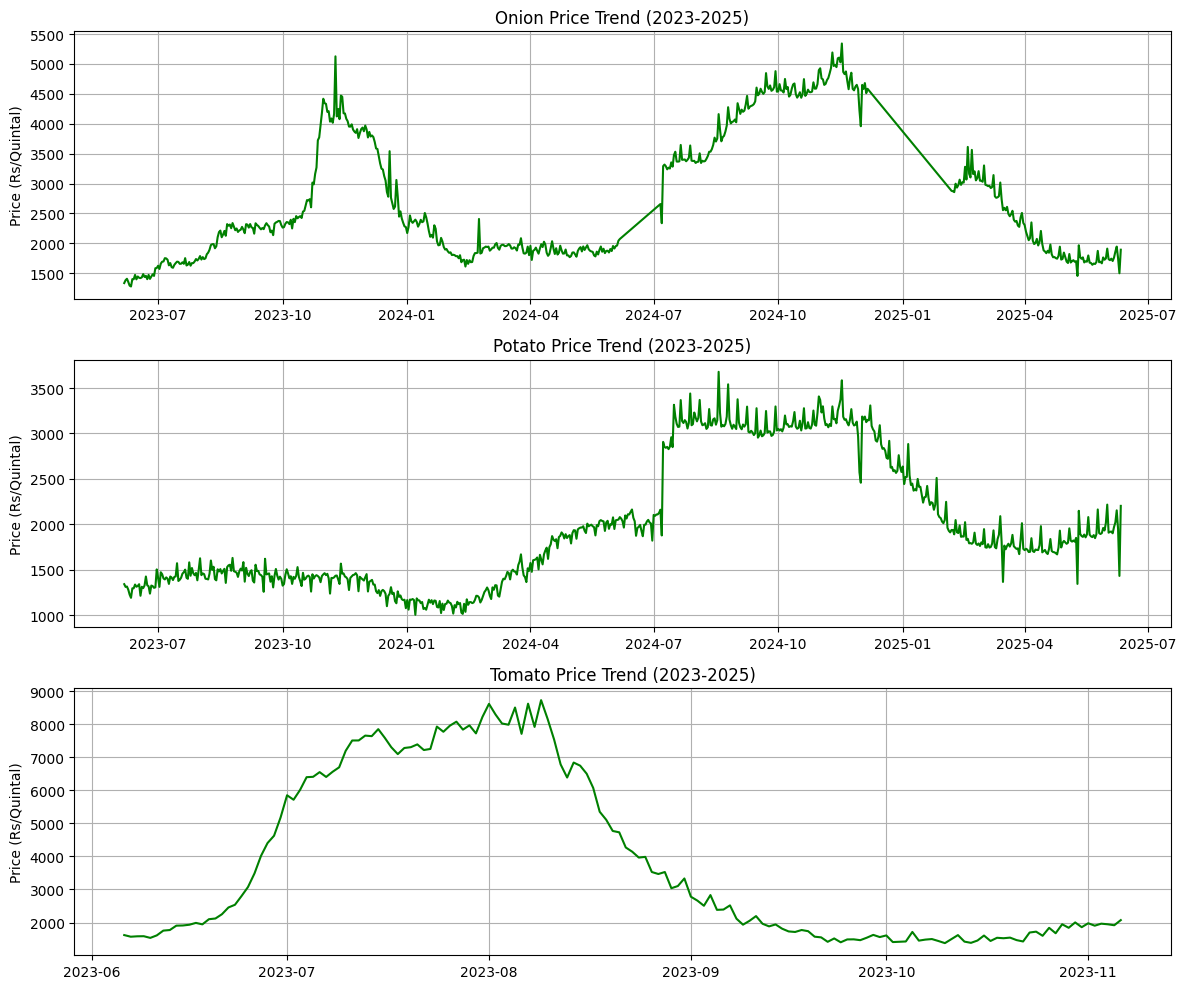

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(12, 10))

for i, crop in enumerate(["Onion", "Potato", "Tomato"]):
    crop_df = df_agg[df_agg["Commodity"] == crop]
    axes[i].plot(crop_df["Price Date"], crop_df["Modal_Price"], color="green")
    axes[i].set_title(f"{crop} Price Trend (2023-2025)")
    axes[i].set_ylabel("Price (Rs/Quintal)")
    axes[i].grid(True)

plt.tight_layout()
plt.savefig("/kaggle/working/price_trends.png", dpi=150)
plt.show()

In [6]:
!pip install prophet statsmodels scikit-learn -q

In [7]:
import pandas as pd
import numpy as np
from statsmodels.tsa.arima.model import ARIMA
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from prophet import Prophet
import warnings
warnings.filterwarnings("ignore")

results = []

for crop in ["Onion", "Potato", "Tomato"]:
    # Load cleaned data
    df = pd.read_csv(f"/kaggle/working/{crop.lower()}_clean.csv")
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date").reset_index(drop=True)
    
    # Train/test split: last 60 days as test
    train = df[:-60]
    test = df[-60:]
    
    # ---- ARIMA ----
    try:
        arima_model = ARIMA(train["price"], order=(1,1,1))
        arima_fit = arima_model.fit()
        arima_pred = arima_fit.forecast(steps=60).values
        
        mae_a = mean_absolute_error(test["price"], arima_pred)
        rmse_a = np.sqrt(mean_squared_error(test["price"], arima_pred))
        mape_a = np.mean(np.abs((test["price"].values - arima_pred) / test["price"].values)) * 100
        results.append({"Crop": crop, "Model": "ARIMA", "MAE": mae_a, "RMSE": rmse_a, "MAPE": mape_a})
    except Exception as e:
        print(f"{crop} ARIMA failed: {e}")
    
    # ---- Random Forest ----
    try:
        df_rf = df.copy()
        for lag in range(1, 8):
            df_rf[f"lag_{lag}"] = df_rf["price"].shift(lag)
        df_rf = df_rf.dropna()
        
        X = df_rf[[f"lag_{i}" for i in range(1, 8)]]
        y = df_rf["price"]
        X_train, X_test = X[:-60], X[-60:]
        y_train, y_test = y[:-60], y[-60:]
        
        rf = RandomForestRegressor(n_estimators=100, random_state=42)
        rf.fit(X_train, y_train)
        rf_pred = rf.predict(X_test)
        
        mae_r = mean_absolute_error(y_test, rf_pred)
        rmse_r = np.sqrt(mean_squared_error(y_test, rf_pred))
        mape_r = np.mean(np.abs((y_test.values - rf_pred) / y_test.values)) * 100
        results.append({"Crop": crop, "Model": "RandomForest", "MAE": mae_r, "RMSE": rmse_r, "MAPE": mape_r})
    except Exception as e:
        print(f"{crop} RF failed: {e}")
    
    # ---- Prophet ----
    try:
        prophet_df = df.rename(columns={"date": "ds", "price": "y"})
        train_p = prophet_df[:-60]
        test_p = prophet_df[-60:]
        
        m = Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False)
        m.fit(train_p)
        future = m.make_future_dataframe(periods=60)
        forecast = m.predict(future)
        prophet_pred = forecast["yhat"].iloc[-60:].values
        
        mae_p = mean_absolute_error(test_p["y"], prophet_pred)
        rmse_p = np.sqrt(mean_squared_error(test_p["y"], prophet_pred))
        mape_p = np.mean(np.abs((test_p["y"].values - prophet_pred) / test_p["y"].values)) * 100
        results.append({"Crop": crop, "Model": "Prophet", "MAE": mae_p, "RMSE": rmse_p, "MAPE": mape_p})
    except Exception as e:
        print(f"{crop} Prophet failed: {e}")

# Results table
results_df = pd.DataFrame(results)
results_df = results_df.round(2)
print("\n===== MODEL COMPARISON =====")
print(results_df.to_string(index=False))

results_df.to_csv("/kaggle/working/model_comparison.csv", index=False)
print("\nSaved to /kaggle/working/model_comparison.csv")

Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
15:56:57 - cmdstanpy - INFO - Chain [1] start processing
15:56:58 - cmdstanpy - INFO - Chain [1] done processing
Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
15:56:59 - cmdstanpy - INFO - Chain [1] start processing
15:56:59 - cmdstanpy - INFO - Chain [1] done processing
Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent o


===== MODEL COMPARISON =====
  Crop        Model      MAE     RMSE    MAPE
 Onion        ARIMA   252.42   272.74   14.70
 Onion RandomForest    95.77   127.82    5.43
 Onion      Prophet   464.41   490.93   26.71
Potato        ARIMA   155.96   195.76    8.20
Potato RandomForest    89.88   151.40    4.95
Potato      Prophet   318.76   401.96   16.43
Tomato        ARIMA   292.98   372.45   16.64
Tomato RandomForest   333.74   364.44   20.78
Tomato      Prophet 20601.46 26975.95 1336.10

Saved to /kaggle/working/model_comparison.csv


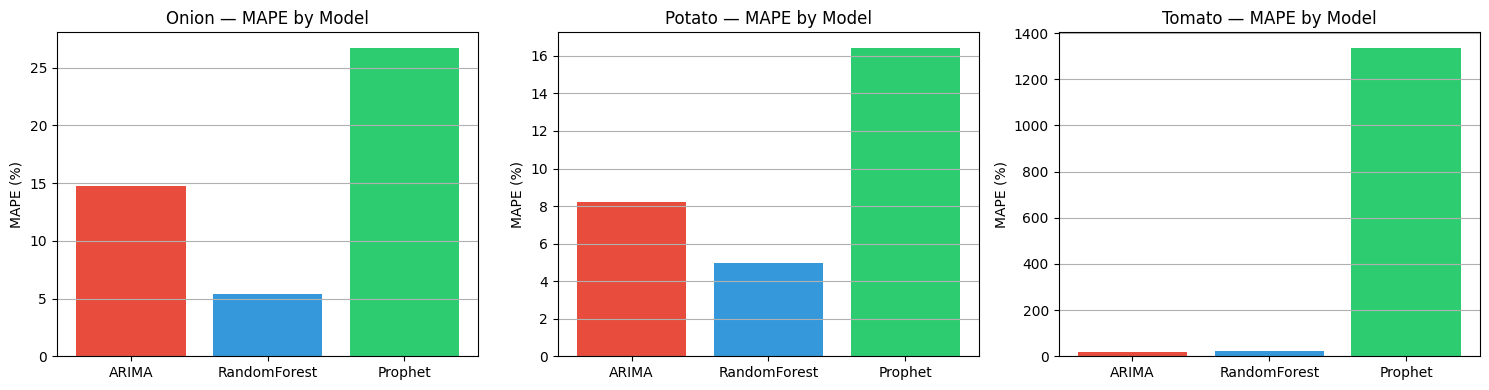

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, crop in enumerate(["Onion", "Potato", "Tomato"]):
    crop_results = results_df[results_df["Crop"] == crop]
    axes[i].bar(crop_results["Model"], crop_results["MAPE"], color=["#e74c3c", "#3498db", "#2ecc71"])
    axes[i].set_title(f"{crop} — MAPE by Model")
    axes[i].set_ylabel("MAPE (%)")
    axes[i].grid(axis="y")

plt.tight_layout()
plt.savefig("/kaggle/working/model_comparison.png", dpi=150)
plt.show()

15:57:10 - cmdstanpy - INFO - Chain [1] start processing
15:57:10 - cmdstanpy - INFO - Chain [1] done processing


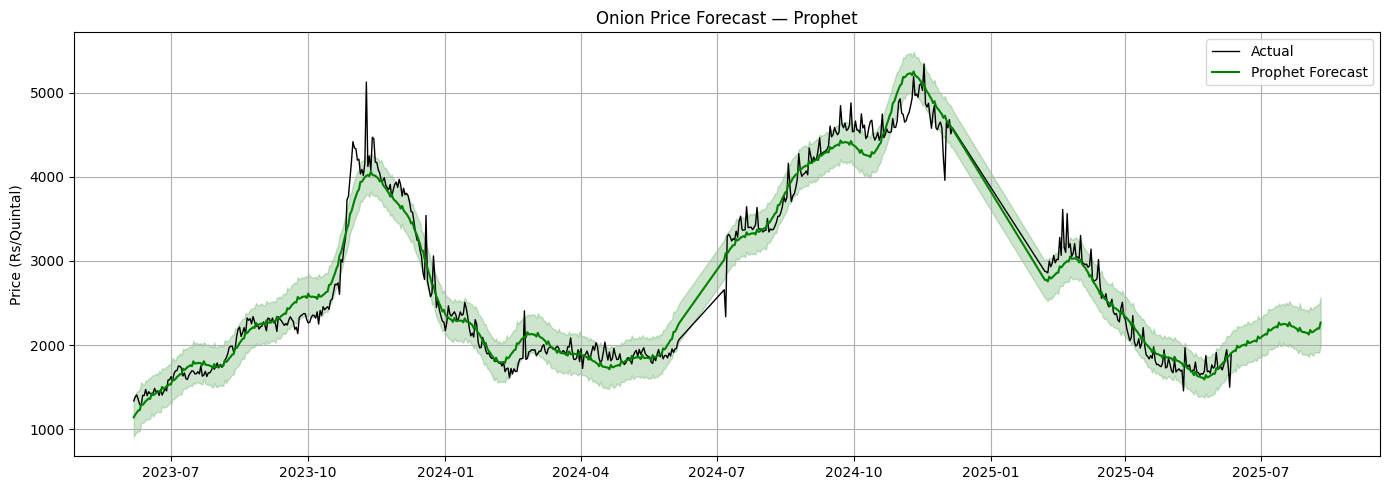

In [9]:
# Pick one crop for detailed view
crop = "Onion"
df = pd.read_csv(f"/kaggle/working/{crop.lower()}_clean.csv")
df["date"] = pd.to_datetime(df["date"])

# Prophet forecast
prophet_df = df.rename(columns={"date": "ds", "price": "y"})
m = Prophet(yearly_seasonality=True, weekly_seasonality=True)
m.fit(prophet_df)
future = m.make_future_dataframe(periods=60)
forecast = m.predict(future)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(prophet_df["ds"], prophet_df["y"], label="Actual", color="black", linewidth=1)
ax.plot(forecast["ds"], forecast["yhat"], label="Prophet Forecast", color="green", linewidth=1.5)
ax.fill_between(forecast["ds"], forecast["yhat_lower"], forecast["yhat_upper"], alpha=0.2, color="green")
ax.set_title(f"{crop} Price Forecast — Prophet")
ax.set_ylabel("Price (Rs/Quintal)")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.savefig("/kaggle/working/onion_forecast.png", dpi=150)
plt.show()

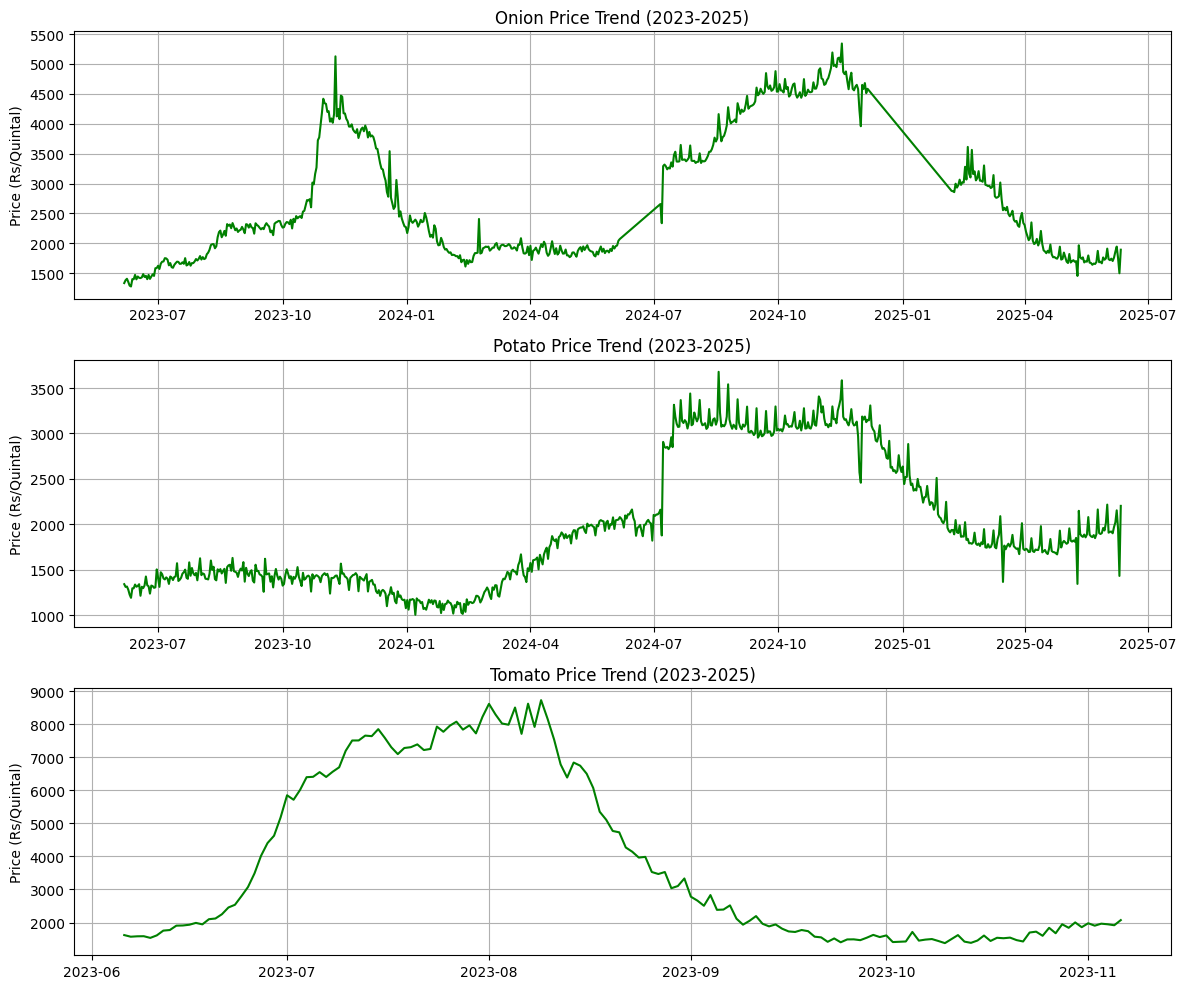

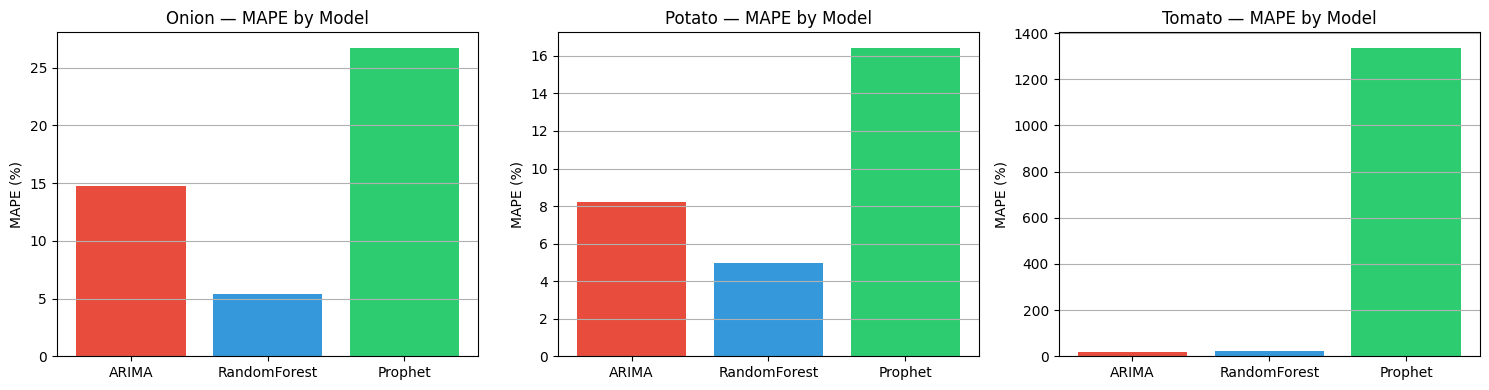

15:57:26 - cmdstanpy - INFO - Chain [1] start processing
15:57:27 - cmdstanpy - INFO - Chain [1] done processing


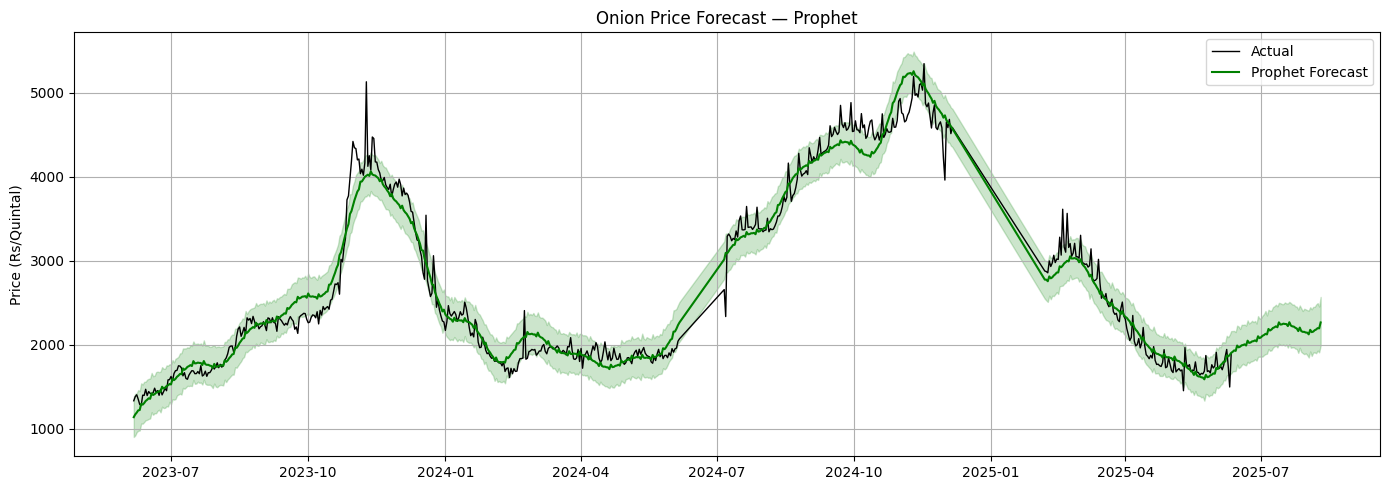

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from prophet import Prophet

# 1. Price trend for all 3 commodities
df_agg = pd.read_csv("/kaggle/working/onion_clean.csv")  # just for structure
df_all = []
for crop in ["Onion", "Potato", "Tomato"]:
    d = pd.read_csv(f"/kaggle/working/{crop.lower()}_clean.csv")
    d["Commodity"] = crop
    df_all.append(d)
df_all = pd.concat(df_all)
df_all["date"] = pd.to_datetime(df_all["date"])

fig, axes = plt.subplots(3, 1, figsize=(12, 10))
for i, crop in enumerate(["Onion", "Potato", "Tomato"]):
    crop_df = df_all[df_all["Commodity"] == crop]
    axes[i].plot(crop_df["date"], crop_df["price"], color="green")
    axes[i].set_title(f"{crop} Price Trend (2023-2025)")
    axes[i].set_ylabel("Price (Rs/Quintal)")
    axes[i].grid(True)
plt.tight_layout()
plt.savefig("/kaggle/working/fig1_price_trends.png", dpi=150)
plt.show()

# 2. Model comparison bar chart
results_df = pd.read_csv("/kaggle/working/model_comparison.csv")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, crop in enumerate(["Onion", "Potato", "Tomato"]):
    cr = results_df[results_df["Crop"] == crop]
    axes[i].bar(cr["Model"], cr["MAPE"], color=["#e74c3c", "#3498db", "#2ecc71"])
    axes[i].set_title(f"{crop} — MAPE by Model")
    axes[i].set_ylabel("MAPE (%)")
    axes[i].grid(axis="y")
plt.tight_layout()
plt.savefig("/kaggle/working/fig2_model_comparison.png", dpi=150)
plt.show()

# 3. Forecast vs actual for Onion (Prophet)
df = pd.read_csv("/kaggle/working/onion_clean.csv")
df["date"] = pd.to_datetime(df["date"])
prophet_df = df.rename(columns={"date": "ds", "price": "y"})
m = Prophet(yearly_seasonality=True, weekly_seasonality=True)
m.fit(prophet_df)
future = m.make_future_dataframe(periods=60)
forecast = m.predict(future)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(prophet_df["ds"], prophet_df["y"], label="Actual", color="black", linewidth=1)
ax.plot(forecast["ds"], forecast["yhat"], label="Prophet Forecast", color="green", linewidth=1.5)
ax.fill_between(forecast["ds"], forecast["yhat_lower"], forecast["yhat_upper"], alpha=0.2, color="green")
ax.set_title("Onion Price Forecast — Prophet")
ax.set_ylabel("Price (Rs/Quintal)")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.savefig("/kaggle/working/fig3_onion_forecast.png", dpi=150)
plt.show()

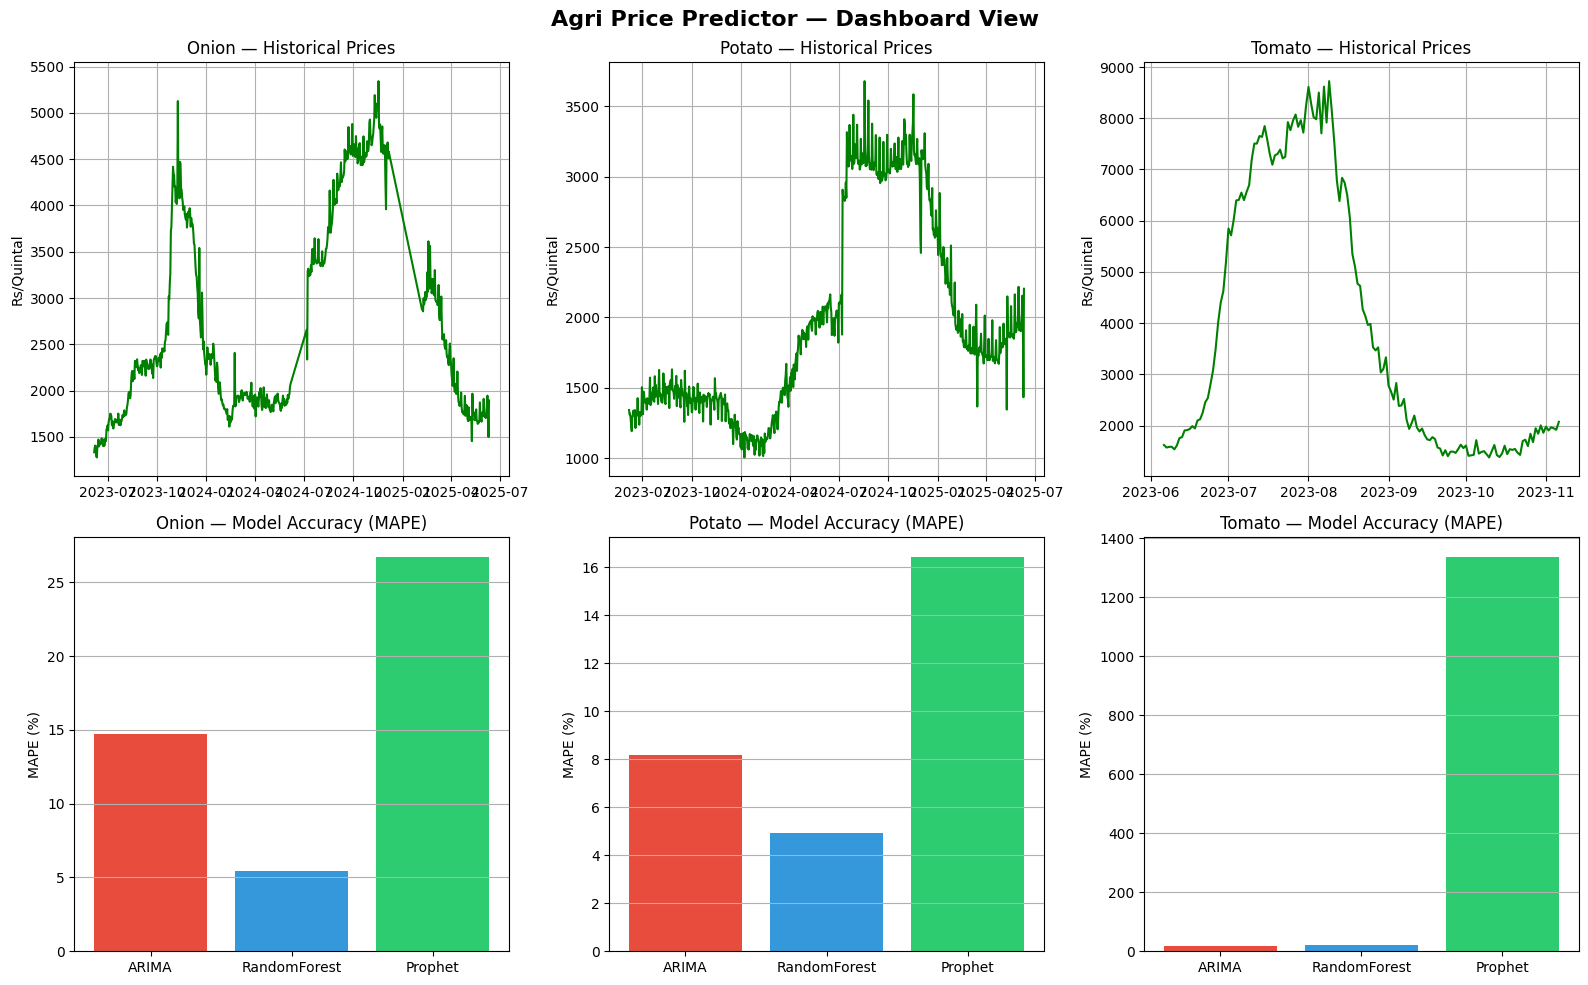

In [11]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(16, 10))
gs = gridspec.GridSpec(2, 3, figure=fig)

# Top row: price trends
for i, crop in enumerate(["Onion", "Potato", "Tomato"]):
    ax = fig.add_subplot(gs[0, i])
    crop_df = df_all[df_all["Commodity"] == crop]
    ax.plot(crop_df["date"], crop_df["price"], color="green")
    ax.set_title(f"{crop} — Historical Prices")
    ax.set_ylabel("Rs/Quintal")
    ax.grid(True)

# Bottom row: MAPE comparison
for i, crop in enumerate(["Onion", "Potato", "Tomato"]):
    ax = fig.add_subplot(gs[1, i])
    cr = results_df[results_df["Crop"] == crop]
    ax.bar(cr["Model"], cr["MAPE"], color=["#e74c3c", "#3498db", "#2ecc71"])
    ax.set_title(f"{crop} — Model Accuracy (MAPE)")
    ax.set_ylabel("MAPE (%)")
    ax.grid(axis="y")

plt.suptitle("Agri Price Predictor — Dashboard View", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig("/kaggle/working/fig4_dashboard.png", dpi=150)
plt.show()

In [12]:
# Pivot table for cleaner report format
pivot = results_df.pivot(index="Crop", columns="Model", values="MAPE")
print("\n===== MAPE COMPARISON (%) =====")
print(pivot.round(2).to_string())

# Also show RMSE
pivot_rmse = results_df.pivot(index="Crop", columns="Model", values="RMSE")
print("\n===== RMSE COMPARISON =====")
print(pivot_rmse.round(2).to_string())

# Save for report
pivot.round(2).to_csv("/kaggle/working/mape_table.csv")
pivot_rmse.round(2).to_csv("/kaggle/working/rmse_table.csv")


===== MAPE COMPARISON (%) =====
Model   ARIMA  Prophet  RandomForest
Crop                                
Onion   14.70    26.71          5.43
Potato   8.20    16.43          4.95
Tomato  16.64  1336.10         20.78

===== RMSE COMPARISON =====
Model    ARIMA   Prophet  RandomForest
Crop                                  
Onion   272.74    490.93        127.82
Potato  195.76    401.96        151.40
Tomato  372.45  26975.95        364.44


In [26]:

!pip install openai -q

import os
from openai import OpenAI
from kaggle_secrets import UserSecretsClient

# This securely loads the key you just saved in Kaggle Secrets
user_secrets = UserSecretsClient()
os.environ["OPENAI_API_KEY"] = user_secrets.get_secret("OPENAI_API_KEY")

# Initialize the client
client = OpenAI()

In [27]:
!pip install groq -q

import os
import pandas as pd
import numpy as np
from datetime import datetime
from sklearn.ensemble import RandomForestRegressor
from statsmodels.tsa.arima.model import ARIMA
from prophet import Prophet
import warnings
warnings.filterwarnings("ignore")

# ============================================================
# 1. SECURE API KEY SETUP (Using Groq - 100% Free)
# ============================================================
from kaggle_secrets import UserSecretsClient
from groq import Groq

try:
    user_secrets = UserSecretsClient()
    os.environ["GROQ_API_KEY"] = user_secrets.get_secret("GROQ_API_KEY")
    client = Groq()  # Groq client
    print("Groq API Key loaded successfully.")
except Exception as e:
    print(f"Error loading API key: {e}")

# ============================================================
# 2. LIVE PROMPT GENERATOR
# ============================================================
def generate_live_prompt(crop, price_history, forecast, model_name):
    recent_prices = [round(float(p), 2) for p in price_history[-5:].tolist()]
    avg_price = round(float(price_history.mean()), 2)
    last_price = round(float(price_history.iloc[-1]), 2)
    forecast_avg = round(float(np.mean(forecast)), 2)
    trend = "upward" if forecast_avg > last_price else "downward"
    pct_change = round(((forecast_avg - last_price) / last_price) * 100, 2)

    prompt = f"""
You are an agricultural commodity price analyst for India.
Live data for {crop} (best model: {model_name}):
- Last 5 days prices (Rs/quintal): {recent_prices}
- 30-day average: {avg_price}
- Latest price: {last_price}
- Forecast (next 30 days average): {forecast_avg}
- Predicted trend: {trend} ({pct_change}% change)
- Date: {datetime.now().strftime('%Y-%m-%d')}

Task (answer in under 150 words):
1. Explain the likely cause of this trend in 2-3 sentences.
2. Recommend whether farmers should sell now or hold.
3. Suggest one policy intervention.
"""
    return prompt

# ============================================================
# 3. LLM QUERY (Using Groq's free model)
# ============================================================
def query_llm(prompt, max_tokens=250):
    try:
        response = client.chat.completions.create(
            model="openai/gpt-oss-20b",  # Changed from llama-3.1-8b-instant
            messages=[{"role": "user", "content": prompt}],
            temperature=0.3,
            max_tokens=max_tokens
        )
        return response.choices[0].message.content
    except Exception as e:
        return f"LLM Error: {e}"

# ============================================================
# 4. INNOVATIVE ALGORITHM: LLM-Weighted Dynamic Ensemble
# ============================================================
def get_model_predictions(crop):
    df = pd.read_csv(f"/kaggle/working/{crop.lower()}_clean.csv")
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date").reset_index(drop=True)
    predictions = {}

    # ARIMA
    try:
        arima_fit = ARIMA(df["price"], order=(1,1,1)).fit()
        predictions["ARIMA"] = arima_fit.forecast(steps=30).values.tolist()
    except Exception:
        predictions["ARIMA"] = [float(df["price"].iloc[-1])] * 30

    # Random Forest
    try:
        df_rf = df.copy()
        for lag in range(1, 8):
            df_rf[f"lag_{lag}"] = df_rf["price"].shift(lag)
        df_rf = df_rf.dropna()
        X = df_rf[[f"lag_{i}" for i in range(1, 8)]]
        y = df_rf["price"]
        rf = RandomForestRegressor(n_estimators=100, random_state=42)
        rf.fit(X[:-30], y[:-30])
        last_row = X.iloc[-1:].values
        rf_preds = []
        for _ in range(30):
            pred = rf.predict(last_row)[0]
            rf_preds.append(pred)
            last_row = np.array([[pred] + list(last_row[0][:-1])])
        predictions["RandomForest"] = [float(p) for p in rf_preds]
    except Exception:
        predictions["RandomForest"] = [float(df["price"].iloc[-1])] * 30

    # Prophet
    try:
        prophet_df = df.rename(columns={"date": "ds", "price": "y"})
        m = Prophet(yearly_seasonality=False, weekly_seasonality=True)
        m.fit(prophet_df)
        future = m.make_future_dataframe(periods=30)
        forecast = m.predict(future)
        predictions["Prophet"] = forecast["yhat"].iloc[-30:].tolist()
    except Exception:
        predictions["Prophet"] = [float(df["price"].iloc[-1])] * 30

    return df["price"], predictions

def llm_weighted_ensemble(predictions_dict, crop, recent_prices):
    prompt = f"""
You are an expert in agricultural price forecasting for India.
Context for {crop}:
- Last 5 actual prices: {[round(float(p), 2) for p in recent_prices[-5:]]}
- ARIMA next-5 forecast: {[round(p, 2) for p in predictions_dict['ARIMA'][:5]]}
- RandomForest next-5 forecast: {[round(p, 2) for p in predictions_dict['RandomForest'][:5]]}
- Prophet next-5 forecast: {[round(p, 2) for p in predictions_dict['Prophet'][:5]]}

Assign a weight (0.0 to 1.0, summing to 1.0) to each model based on which 
forecast best matches the observed price behaviour and Indian agri seasonality.

Respond ONLY in this exact format, one per line:
ARIMA: 0.XX
RandomForest: 0.XX
Prophet: 0.XX
"""
    try:
        response = query_llm(prompt, max_tokens=1000)
        weights = {}
        for line in response.strip().split("\n"):
            if ":" in line:
                k, v = line.split(":")
                weights[k.strip()] = float(v.strip())
        total = sum(weights.values())
        if total > 0:
            weights = {k: v / total for k, v in weights.items()}
        else:
            weights = {"ARIMA": 1/3, "RandomForest": 1/3, "Prophet": 1/3}
    except Exception:
        weights = {"ARIMA": 1/3, "RandomForest": 1/3, "Prophet": 1/3}

    ensemble = sum(weights[m] * np.array(predictions_dict[m]) for m in weights.keys())
    return ensemble.tolist(), weights

# ============================================================
# 5. RUN THE PIPELINE
# ============================================================
print("=" * 60)
print("LLM-WEIGHTED DYNAMIC ENSEMBLE — SIH1647 (FREE GROQ)")
print("=" * 60)

all_results = []

for crop in ["Onion", "Potato", "Tomato"]:
    print(f"\n--- {crop} ---")
    try:
        recent_prices, preds = get_model_predictions(crop)
        ensemble_forecast, weights = llm_weighted_ensemble(preds, crop, recent_prices)

        print(f"LLM-assigned weights: {weights}")
        print(f"Ensemble next-5 forecast: {[round(p, 2) for p in ensemble_forecast[:5]]}")

        all_results.append({
            "Crop": crop,
            "ARIMA_weight": weights.get("ARIMA", 0),
            "RF_weight": weights.get("RandomForest", 0),
            "Prophet_weight": weights.get("Prophet", 0),
        })

        best_model = max(weights, key=weights.get)
        prompt = generate_live_prompt(crop, recent_prices, ensemble_forecast, best_model)
        
        print("\nLive prompt sent to LLM:")
        print(prompt.strip())
        
        print("\nLLM response:")
        print(query_llm(prompt))
        print("-" * 40)
    except Exception as e:
        print(f"Error processing {crop}: {e}")

if all_results:
    ensemble_df = pd.DataFrame(all_results)
    ensemble_df.to_csv("/kaggle/working/llm_ensemble_results.csv", index=False)
    print("\nSaved to /kaggle/working/llm_ensemble_results.csv")

Groq API Key loaded successfully.
LLM-WEIGHTED DYNAMIC ENSEMBLE — SIH1647 (FREE GROQ)

--- Onion ---


16:28:55 - cmdstanpy - INFO - Chain [1] start processing
16:28:55 - cmdstanpy - INFO - Chain [1] done processing


LLM-assigned weights: {'ARIMA': 0.6, 'RandomForest': 0.3, 'Prophet': 0.1}
Ensemble next-5 forecast: [1732.83, 1706.55, 1699.14, 1709.58, 1710.53]

Live prompt sent to LLM:
You are an agricultural commodity price analyst for India.
Live data for Onion (best model: ARIMA):
- Last 5 days prices (Rs/quintal): [1860.61, 1945.19, 1749.73, 1498.78, 1893.05]
- 30-day average: 2732.21
- Latest price: 1893.05
- Forecast (next 30 days average): 1689.09
- Predicted trend: downward (-10.77% change)
- Date: 2026-10-26

Task (answer in under 150 words):
1. Explain the likely cause of this trend in 2-3 sentences.
2. Recommend whether farmers should sell now or hold.
3. Suggest one policy intervention.

LLM response:
**1. Likely cause**  
The sharp drop reflects a recent oversupply from the post‑harvest season, coupled with lower domestic demand as the peak consumption period ends. Improved cold‑chain storage has also reduced spoilage, allowing more onions to reach the market, further depressing prices

16:28:57 - cmdstanpy - INFO - Chain [1] start processing
16:28:57 - cmdstanpy - INFO - Chain [1] done processing


LLM-assigned weights: {'ARIMA': 0.45, 'RandomForest': 0.35, 'Prophet': 0.2}
Ensemble next-5 forecast: [1890.96, 1863.56, 1881.58, 1865.13, 1855.84]

Live prompt sent to LLM:
You are an agricultural commodity price analyst for India.
Live data for Potato (best model: ARIMA):
- Last 5 days prices (Rs/quintal): [2022.06, 2154.42, 1947.86, 1433.22, 2203.79]
- 30-day average: 1965.96
- Latest price: 2203.79
- Forecast (next 30 days average): 1857.98
- Predicted trend: downward (-15.69% change)
- Date: 2026-10-26

Task (answer in under 150 words):
1. Explain the likely cause of this trend in 2-3 sentences.
2. Recommend whether farmers should sell now or hold.
3. Suggest one policy intervention.

LLM response:

----------------------------------------

--- Tomato ---


16:28:59 - cmdstanpy - INFO - Chain [1] start processing
16:28:59 - cmdstanpy - INFO - Chain [1] done processing


LLM-assigned weights: {'ARIMA': 0.7, 'RandomForest': 0.3, 'Prophet': 0.0}
Ensemble next-5 forecast: [2034.12, 2044.29, 2046.11, 2060.11, 2076.6]

Live prompt sent to LLM:
You are an agricultural commodity price analyst for India.
Live data for Tomato (best model: ARIMA):
- Last 5 days prices (Rs/quintal): [1905.08, 1965.61, 1947.35, 1918.28, 2073.71]
- 30-day average: 3828.4
- Latest price: 2073.71
- Forecast (next 30 days average): 2091.12
- Predicted trend: upward (0.84% change)
- Date: 2026-10-26

Task (answer in under 150 words):
1. Explain the likely cause of this trend in 2-3 sentences.
2. Recommend whether farmers should sell now or hold.
3. Suggest one policy intervention.

LLM response:

----------------------------------------

Saved to /kaggle/working/llm_ensemble_results.csv
